# Deep Learning for 4-Class Motor Imagery Decoding

## 1. Objective

The goal of this module is to develop and evaluate an EEGNet-based neural decoder for four motor-imagery tasks: **left hand, right hand, feet, and tongue**, using EEG recordings from the BCI Competition IV 2a dataset.

The primary evaluation is **cross-subject**: train, validation, and test sets are separated by participant, so no EEG epoch from a test participant is used during model fitting, early stopping, or hyperparameter selection. This protocol estimates how well the decoder transfers to participants not represented during development.

Four-class decoding is more challenging than binary motor-imagery decoding because the neural signatures can overlap spatially and temporally, particularly for hand and foot imagery.

## 2. Pipeline features

* **Subject-wise train/validation/test split:** participants, rather than trials, define the splits. Hyperparameters are selected using validation participants only; final metrics are computed once on held-out test participants.
* **Explicit event mapping:** event IDs are passed explicitly to MNE (`left=1`, `right=2`, `feet=3`, `tongue=4`). This prevents an unintended alphabetical mapping of annotation labels to numeric IDs.
* **EEGNet architecture:** a compact CNN that combines temporal convolutions with depthwise spatial and separable convolutions to learn spatiotemporal EEG representations.
* **Per-trial, per-channel Z-score normalization:** each channel is standardised across time within each epoch, stabilising optimisation while retaining within-trial spatial differences.
* **Training-only Gaussian augmentation:** white noise is added only to copies of training epochs. Its effect is assessed through an ablation experiment rather than assumed.
* **Training-set class weights:** weights are computed using training labels only. As the original dataset is balanced, they are expected to be close to 1 and act only as a safeguard if preprocessing removes epochs unevenly.
* **Group-aware hyperparameter search:** learning rate, dropout, and batch size are selected using validation participants only. Test participants remain untouched until final evaluation.
* **Optional LOSO analysis:** after the final architecture and hyperparameters are fixed, a Leave-One-Subject-Out analysis can be used to report performance variability across individual held-out participants.

## 3. Signal-processing specifications

* **Bandwidth:** 1–40 Hz, set during preprocessing.
* **Epoch window:** 0.5–3.5 s after the cue, yielding a 3-second motor-imagery interval.
* **Sampling rate:** 250 Hz.
* **Input shape:** 22 channels × 751 samples × 1.

## Setup and configuration

In [2]:
import os, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import tensorflow as tf
from scipy.signal import hilbert
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.utils import class_weight
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Activation, Dropout, Conv2D, AveragePooling2D
from tensorflow.keras.layers import SeparableConv2D, DepthwiseConv2D, BatchNormalization, Flatten, Input
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam

#Reproducibility
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
set_seed()

# Data 
CLEAN_DATA_DIR = os.path.join('.', 'cleaned_data_1_40')
FS = 250
EVENT_ID = {'left': 1, 'right': 2, 'foot': 3, 'tongue': 4}   # label = id - 1
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Foot', 'Tongue']  # index = label
T_MIN, T_MAX = 0.5, 3.5
ALL_SUBJECTS = [f'A{i:02d}T' for i in range(1, 10)]

# Subject-wise split 
# BCI IV 2a, so the groups mix "easy" and "hard" subjects.
TRAIN_SUBJECTS = ['A01T', 'A03T', 'A05T', 'A06T', 'A08T']
VAL_SUBJECTS   = ['A04T', 'A07T']
TEST_SUBJECTS  = ['A02T', 'A09T']
assert not (set(TRAIN_SUBJECTS) & set(VAL_SUBJECTS) or set(TRAIN_SUBJECTS) & set(TEST_SUBJECTS)
            or set(VAL_SUBJECTS) & set(TEST_SUBJECTS)), 'Subject groups must be disjoint'
assert sorted(TRAIN_SUBJECTS + VAL_SUBJECTS + TEST_SUBJECTS) == sorted(ALL_SUBJECTS)

# Training budget / switches 
NOISE_STD = 0.05
PARAM_GRID = {
    'learning_rate': [0.001, 0.0005, 0.0001],
    'dropout_rate': [0.4, 0.5, 0.6],
    'batch_size': [16, 32],
}
GRID_EPOCHS,  GRID_PATIENCE  = 30, 10
FINAL_EPOCHS, FINAL_PATIENCE = 100, 20
ABL_EPOCHS,   ABL_PATIENCE   = 60, 15
LOSO_EPOCHS,  LOSO_PATIENCE  = 60, 15
RUN_ABLATION = True            # 3 conditions x len(ABLATION_SEEDS) trainings (slow)
ABLATION_SEEDS = [0, 1, 2]
RUN_LOSO = True               # 9 trainings (slow)

## Data loading function

In [3]:
def load_subject(subject_id, band=None):
    """
    Load one cleaned subject, epoch it and z-score each trial/channel.
    band: optional (l_freq, h_freq) extra band-pass applied on the continuous signal (used in the ablation).
    Returns X with shape (n_trials, 22, 751, 1) and y in {0: left, 1: right, 2: foot, 3: tongue}.
    """
    file_path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    raw.pick(['eeg'])                      # 22 EEG channels only (drops EOG)
    if band is not None:
        raw.filter(l_freq=band[0], h_freq=band[1], verbose=False)

    # IMPORTANT: pass event_id explicitly. With event_id=None MNE assigns ids alphabetically
    # (foot=1, left=2, right=3, tongue=4), which would not match CLASS_NAMES.
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=T_MIN, tmax=T_MAX,
                        baseline=None, preload=True, verbose=False)

    X = epochs.get_data(copy=True).astype(np.float32)
    y = epochs.events[:, -1] - 1

    # Z-score per trial and per channel (over time)
    X = (X - X.mean(axis=-1, keepdims=True)) / (X.std(axis=-1, keepdims=True) + 1e-8)
    return X[..., np.newaxis], y

## Loading all subjects (kept separate: no pooling yet)

In [4]:
data = {}
for sub in ALL_SUBJECTS:                  # errors are NOT swallowed: a missing subject must be noticed
    X_sub, y_sub = load_subject(sub)
    data[sub] = (X_sub, y_sub)
    counts = np.bincount(y_sub, minlength=4).tolist()
    print(f'{sub}: X={X_sub.shape}  trials per class (L,R,F,T)={counts}')

def stack(subjects, store=None):
    store = data if store is None else store
    return (np.concatenate([store[s][0] for s in subjects], axis=0),
            np.concatenate([store[s][1] for s in subjects], axis=0))

A01T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A02T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A03T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A04T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A05T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A06T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A07T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A08T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]
A09T: X=(288, 22, 751, 1)  trials per class (L,R,F,T)=[72, 72, 72, 72]


## Sanity check: label mapping and event timing
Before trusting any number, verify two assumptions with a classic neurophysiological signature, the **mu-band (8-12 Hz) event-related desynchronization (ERD)**:

* **Labels:** left-hand imagery should reduce mu power over the *right* motor cortex (C4); right-hand imagery over the *left* one (C3).
* **Timing:** if the annotation onset really is the cue, the ERD should appear shortly after t = 0. If it appears only ~2 s later, the onsets are the trial *starts* (cue at +2 s) and the epoch window must be shifted accordingly (in `T_MIN`/`T_MAX` and in the annotation onset of the preprocessing notebook).

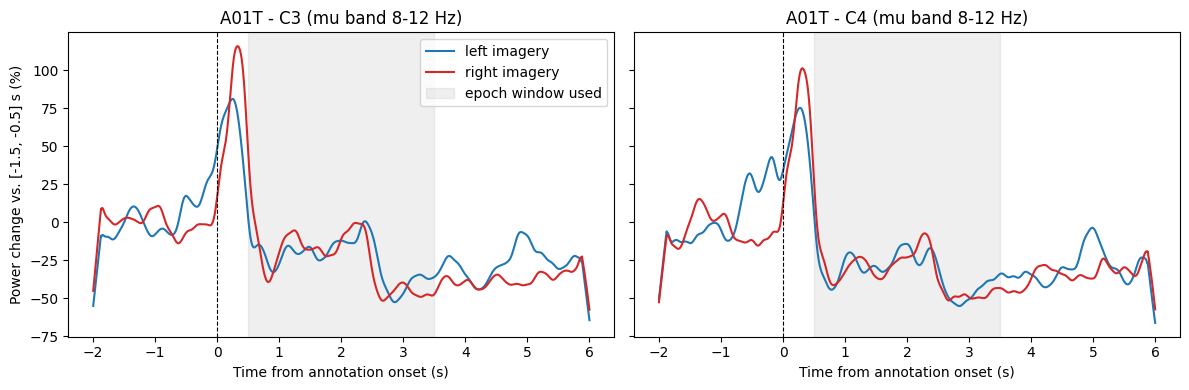

In [5]:
def erd_check(subject_id='A01T', band=(8., 12.), smooth_s=0.25):
    path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(path, preload=True, verbose=False)
    raw.pick(['eeg']).filter(*band, verbose=False)
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    ep = mne.Epochs(raw, events, event_id={'left': 1, 'right': 2}, tmin=-2., tmax=6.,
                    baseline=None, preload=True, verbose=False)
    times = ep.times
    ref = (times >= -1.5) & (times <= -0.5)
    win = int(smooth_s * FS)
    kernel = np.ones(win) / win

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, ch in zip(axes, ['C3', 'C4']):
        for cls, color in [('left', 'tab:blue'), ('right', 'tab:red')]:
            d = ep[cls].copy().pick([ch]).get_data(copy=True)[:, 0, :]
            power = np.abs(hilbert(d, axis=-1)) ** 2
            p = power.mean(axis=0)
            p = np.convolve(p, kernel, mode='same')
            erd = 100 * (p - p[ref].mean()) / p[ref].mean()
            ax.plot(times, erd, color=color, label=f'{cls} imagery')
        ax.axvline(0, color='k', ls='--', lw=0.8)
        ax.axvspan(T_MIN, T_MAX, color='gray', alpha=0.12, label='epoch window used')
        ax.set_title(f'{subject_id} - {ch} (mu band {band[0]:.0f}-{band[1]:.0f} Hz)')
        ax.set_xlabel('Time from annotation onset (s)')
    axes[0].set_ylabel('Power change vs. [-1.5, -0.5] s (%)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()

erd_check('A01T')

## Subject-wise split and Gaussian augmentation (training set only)

In [6]:
def add_gaussian_noise(X, std=NOISE_STD, seed=SEED):
    rng = np.random.default_rng(seed)
    return X + rng.normal(0, std, X.shape).astype(X.dtype)

def augment(X, y, std=NOISE_STD):
    """Original training trials + a noisy copy of them."""
    return np.concatenate([X, add_gaussian_noise(X, std)], axis=0), np.concatenate([y, y], axis=0)

def get_class_weights(y):
    classes = np.unique(y)
    w = class_weight.compute_class_weight('balanced', classes=classes, y=y)
    return {int(c): float(v) for c, v in zip(classes, w)}

X_train, y_train = stack(TRAIN_SUBJECTS)
X_val,   y_val   = stack(VAL_SUBJECTS)
X_test,  y_test  = stack(TEST_SUBJECTS)

X_train_aug, y_train_aug = augment(X_train, y_train)
class_weights_dict = get_class_weights(y_train_aug)

print(f'train: {X_train.shape[0]} trials ({TRAIN_SUBJECTS})  -> {X_train_aug.shape[0]} after augmentation')
print(f'val:   {X_val.shape[0]} trials ({VAL_SUBJECTS})')
print(f'test:  {X_test.shape[0]} trials ({TEST_SUBJECTS})')
print('class weights:', {k: round(v, 3) for k, v in class_weights_dict.items()})

train: 1440 trials (['A01T', 'A03T', 'A05T', 'A06T', 'A08T'])  -> 2880 after augmentation
val:   576 trials (['A04T', 'A07T'])
test:  576 trials (['A02T', 'A09T'])
class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0}


## EEGNet architecture

In [7]:
def EEGNet_Model(nb_classes, Chans=22, Samples=751, dropoutRate=0.5):
    """Standard EEGNet model for multiclass BCI decoding."""
    input1 = Input(shape=(Chans, Samples, 1))
    
    # Block 1: Temporal and Spatial Convolutions
    block1 = Conv2D(8, (1, 64), padding='same', use_bias=False)(input1)
    block1 = BatchNormalization()(block1)
    block1 = DepthwiseConv2D((Chans, 1), use_bias=False, depth_multiplier=2,
                              depthwise_constraint=max_norm(1.))(block1)
    block1 = BatchNormalization()(block1)
    block1 = Activation('elu')(block1)
    block1 = AveragePooling2D((1, 4))(block1)
    block1 = Dropout(dropoutRate)(block1)

    # Block 2: Separable Convolution
    block2 = SeparableConv2D(16, (1, 16), use_bias=False, padding='same')(block1)
    block2 = BatchNormalization()(block2)
    block2 = Activation('elu')(block2)
    block2 = AveragePooling2D((1, 8))(block2)
    block2 = Dropout(dropoutRate)(block2)

    flatten = Flatten()(block2)
    dense = Dense(nb_classes, kernel_constraint=max_norm(0.25))(flatten)
    softmax = Activation('softmax')(dense)
    
    return Model(inputs=input1, outputs=softmax)


def build_and_train(X_tr, y_tr, X_va, y_va, lr, dropout, batch_size, epochs, patience,
                    seed=SEED, verbose=0):
    """Train EEGNet with early stopping on the validation loss (best weights restored)."""
    tf.keras.backend.clear_session()
    set_seed(seed)
    model = EEGNet_Model(nb_classes=4, dropoutRate=dropout)
    model.compile(loss='sparse_categorical_crossentropy',
                  optimizer=Adam(learning_rate=lr), metrics=['accuracy'])
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                                  restore_best_weights=True)]
    history = model.fit(X_tr, y_tr, epochs=epochs, batch_size=int(batch_size),
                        validation_data=(X_va, y_va), class_weight=get_class_weights(y_tr),
                        callbacks=callbacks, verbose=verbose)
    val_acc = model.evaluate(X_va, y_va, verbose=0)[1]
    return model, history, val_acc

## Grid search (scored on the validation subjects only)

In [8]:
keys, values = zip(*PARAM_GRID.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
search_results = []

print(f'Starting grid search: {len(combinations)} combinations, scored on validation subjects {VAL_SUBJECTS}')
for i, params in enumerate(combinations, 1):
    _, _, val_acc = build_and_train(X_train_aug, y_train_aug, X_val, y_val,
                                    lr=params['learning_rate'], dropout=params['dropout_rate'],
                                    batch_size=params['batch_size'],
                                    epochs=GRID_EPOCHS, patience=GRID_PATIENCE)
    search_results.append({**params, 'val_accuracy': val_acc})
    print(f'[{i}/{len(combinations)}] {params} -> val_acc={val_acc:.3f}')

results_df = pd.DataFrame(search_results).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
print('\nGrid Search Rankings (validation subjects):')
print(results_df)

Starting grid search: 18 combinations, scored on validation subjects ['A04T', 'A07T']

[1/18] {'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 16} -> val_acc=0.486
[2/18] {'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 32} -> val_acc=0.493
[3/18] {'learning_rate': 0.001, 'dropout_rate': 0.5, 'batch_size': 16} -> val_acc=0.509
[4/18] {'learning_rate': 0.001, 'dropout_rate': 0.5, 'batch_size': 32} -> val_acc=0.530
[5/18] {'learning_rate': 0.001, 'dropout_rate': 0.6, 'batch_size': 16} -> val_acc=0.510
[6/18] {'learning_rate': 0.001, 'dropout_rate': 0.6, 'batch_size': 32} -> val_acc=0.514
[7/18] {'learning_rate': 0.0005, 'dropout_rate': 0.4, 'batch_size': 16} -> val_acc=0.483
[8/18] {'learning_rate': 0.0005, 'dropout_rate': 0.4, 'batch_size': 32} -> val_acc=0.497
[9/18] {'learning_rate': 0.0005, 'dropout_rate': 0.5, 'batch_size': 16} -> val_acc=0.514
[10/18] {'learning_rate': 0.0005, 'dropout_rate': 0.5, 'batch_size': 32} -> val_acc=0.502
[11/18] {'learning_rate': 0.

## Final training with visual history

Best configuration: LR=0.001, dropout=0.5, batch size=32
Epoch 1/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 21s 184ms/step - accuracy: 0.2986 - loss: 1.3717 - val_accuracy: 0.3194 - val_loss: 1.3771
Epoch 2/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 19s 170ms/step - accuracy: 0.4142 - loss: 1.2885 - val_accuracy: 0.3785 - val_loss: 1.3320
Epoch 3/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.4542 - loss: 1.2242 - val_accuracy: 0.3767 - val_loss: 1.3153
Epoch 4/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 17s 188ms/step - accuracy: 0.4771 - loss: 1.2037 - val_accuracy: 0.3715 - val_loss: 1.3087
Epoch 5/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.4962 - loss: 1.1863 - val_accuracy: 0.4271 - val_loss: 1.2871
Epoch 6/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.5153 - loss: 1.1619 - val_accuracy: 0.4271 - val_loss: 1.2869
Epoch 7/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.5191 - loss: 1.1447 - val_accuracy: 0.4358 - val_loss: 1.2830
Epoch 8/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 

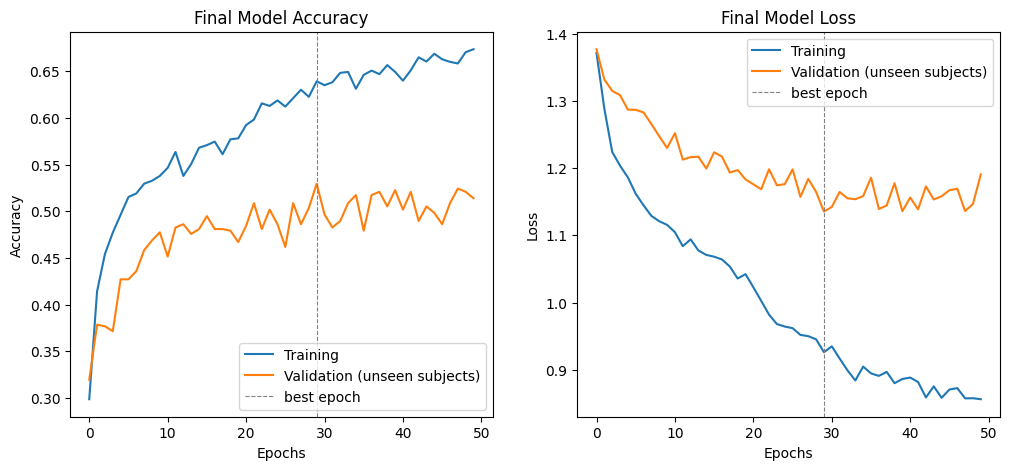

In [9]:
best_params = results_df.iloc[0]
print(f"Best configuration: LR={best_params['learning_rate']}, dropout={best_params['dropout_rate']}, "
      f"batch size={int(best_params['batch_size'])}")

final_model, history, final_val_acc = build_and_train(
    X_train_aug, y_train_aug, X_val, y_val,
    lr=best_params['learning_rate'], dropout=best_params['dropout_rate'],
    batch_size=best_params['batch_size'], epochs=FINAL_EPOCHS, patience=FINAL_PATIENCE, verbose=1)

best_epoch = int(np.argmin(history.history['val_loss']))
print(f'\nBest epoch (lowest val loss): {best_epoch + 1}  |  validation accuracy of restored weights: {final_val_acc:.3f}')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation (unseen subjects)')
plt.axvline(best_epoch, color='gray', ls='--', lw=0.8, label='best epoch')
plt.title('Final Model Accuracy'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation (unseen subjects)')
plt.axvline(best_epoch, color='gray', ls='--', lw=0.8, label='best epoch')
plt.title('Final Model Loss'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()
plt.show()

## Final evaluation on the held-out test subjects 

Test subjects: ['A02T', 'A09T']  (576 trials)  |  chance level = 25%
Test accuracy: 0.470

Final Classification Report:
              precision    recall  f1-score   support

   Left Hand       0.57      0.30      0.39       144
  Right Hand       0.44      0.58      0.50       144
        Foot       0.37      0.54      0.44       144
      Tongue       0.65      0.46      0.54       144

    accuracy                           0.47       576
   macro avg       0.51      0.47      0.47       576
weighted avg       0.51      0.47      0.47       576



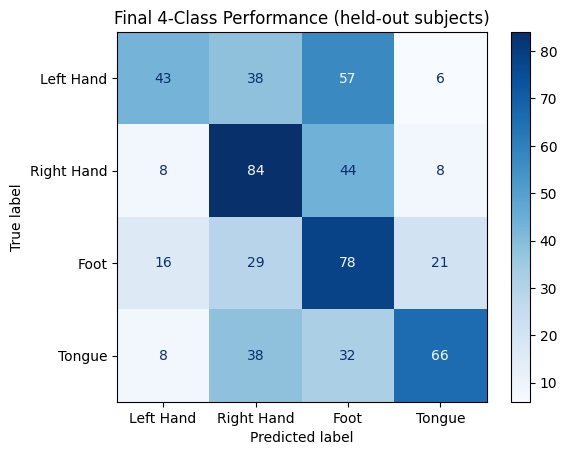

Accuracy per test subject:
  A02T: 0.382
  A09T: 0.559

Model exported successfully as final_eegnet_bci_model.keras


In [10]:
y_pred = np.argmax(final_model.predict(X_test, verbose=0), axis=1)
test_acc = float(np.mean(y_pred == y_test))

print(f'Test subjects: {TEST_SUBJECTS}  ({len(y_test)} trials)  |  chance level = 25%')
print(f'Test accuracy: {test_acc:.3f}\n')
print('Final Classification Report:')
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(cmap='Blues', values_format='d')
plt.title('Final 4-Class Performance (held-out subjects)')
plt.show()

print('Accuracy per test subject:')
for s in TEST_SUBJECTS:
    print(f'  {s}: {final_model.evaluate(*data[s], verbose=0)[1]:.3f}')

final_model.save('final_eegnet_bci_model.keras')
print('\nModel exported successfully as final_eegnet_bci_model.keras')

## Ablation: what do augmentation and bandwidth actually change?
Claims such as "Gaussian augmentation improves generalization" or "1-40 Hz is better than 8-30 Hz" are tested here, on the **validation** subjects (never on the test subjects), with the best hyper-parameters and several seeds. 

In [11]:
if RUN_ABLATION:
    data_8_30 = {s: load_subject(s, band=(8., 30.)) for s in ALL_SUBJECTS}

    def run_condition(name, store, use_aug):
        X_tr, y_tr = stack(TRAIN_SUBJECTS, store)
        X_va, y_va = stack(VAL_SUBJECTS, store)
        if use_aug:
            X_tr, y_tr = augment(X_tr, y_tr)
        accs = []
        for seed in ABLATION_SEEDS:
            _, _, acc = build_and_train(X_tr, y_tr, X_va, y_va,
                                        lr=best_params['learning_rate'], dropout=best_params['dropout_rate'],
                                        batch_size=best_params['batch_size'],
                                        epochs=ABL_EPOCHS, patience=ABL_PATIENCE, seed=seed)
            accs.append(acc)
            print(f'  {name} | seed {seed}: val_acc={acc:.3f}')
        return {'condition': name, 'val_acc_mean': np.mean(accs), 'val_acc_std': np.std(accs), 'n_seeds': len(accs)}

    ablation_df = pd.DataFrame([
        run_condition('1-40 Hz, no augmentation', data, False),
        run_condition('1-40 Hz + Gaussian noise', data, True),
        run_condition('8-30 Hz, no augmentation', data_8_30, False),
    ])
    print('\nAblation (validation subjects):')
    print(ablation_df.round(3).to_string(index=False))
else:
    print('RUN_ABLATION=False: skipped.')

  1-40 Hz, no augmentation | seed 0: val_acc=0.566
  1-40 Hz, no augmentation | seed 1: val_acc=0.514
  1-40 Hz, no augmentation | seed 2: val_acc=0.512
  1-40 Hz + Gaussian noise | seed 0: val_acc=0.557
  1-40 Hz + Gaussian noise | seed 1: val_acc=0.543
  1-40 Hz + Gaussian noise | seed 2: val_acc=0.502
  8-30 Hz, no augmentation | seed 0: val_acc=0.347
  8-30 Hz, no augmentation | seed 1: val_acc=0.335
  8-30 Hz, no augmentation | seed 2: val_acc=0.368

Ablation (validation subjects):
               condition  val_acc_mean  val_acc_std  n_seeds
1-40 Hz, no augmentation         0.531        0.025        3
1-40 Hz + Gaussian noise         0.534        0.024        3
8-30 Hz, no augmentation         0.350        0.014        3


## Leave-one-subject-out (LOSO) evaluation
Each subject is held out in turn as test set; the next subject (cyclically) is used as validation set for early stopping and the remaining seven for training. The hyper-parameters come from the grid search above, which used `VAL_SUBJECTS` for scoring, so the LOSO figures are only mildly optimistic for those two subjects. Set `RUN_LOSO = True` in the configuration cell to run it.

Starting Leave-One-Subject-Out (LOSO) Evaluation with Detailed Reporting...


Fold 1/9 | Test Subject: A01T | Validation Subject: A02T

--- Training Condition: NoAug ---
Classification Report for Subject A01T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.49      0.49      0.49        72
  Right Hand       0.53      0.46      0.49        72
        Foot       0.49      0.51      0.50        72
      Tongue       0.65      0.71      0.68        72

    accuracy                           0.54       288
   macro avg       0.54      0.54      0.54       288
weighted avg       0.54      0.54      0.54       288


--- Training Condition: Aug ---
Classification Report for Subject A01T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.67      0.31      0.42        72
  Right Hand       0.66      0.65      0.66        72
        Foot       0.49      0.68      0.57        72
      Tongue       0.59      0.69      0.64        

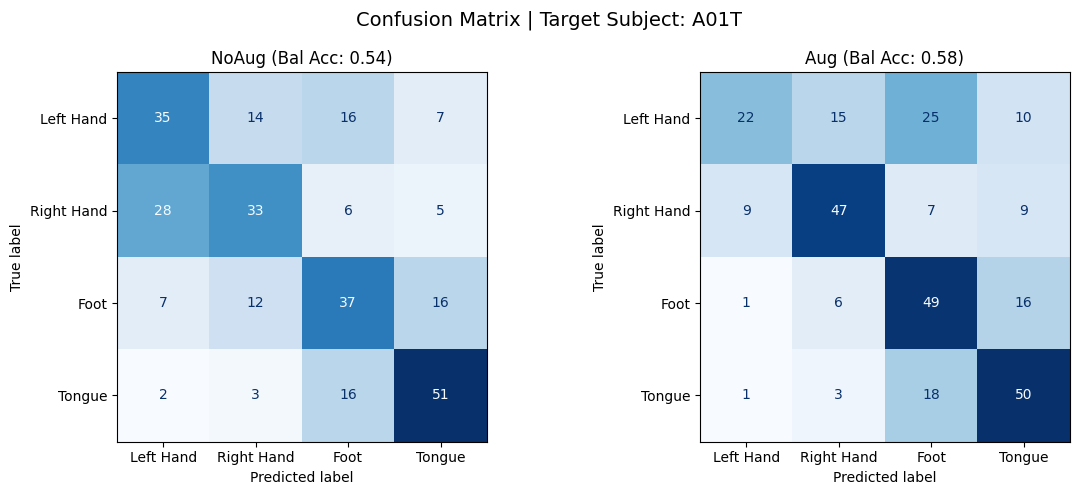


Fold 2/9 | Test Subject: A02T | Validation Subject: A03T

--- Training Condition: NoAug ---
Classification Report for Subject A02T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.59      0.24      0.34        72
  Right Hand       0.46      0.50      0.48        72
        Foot       0.39      0.79      0.52        72
      Tongue       0.54      0.26      0.36        72

    accuracy                           0.45       288
   macro avg       0.50      0.45      0.42       288
weighted avg       0.50      0.45      0.42       288


--- Training Condition: Aug ---
Classification Report for Subject A02T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.56      0.21      0.30        72
  Right Hand       0.42      0.54      0.47        72
        Foot       0.41      0.51      0.45        72
      Tongue       0.43      0.46      0.44        72

    accuracy                           0.43       288
   macro avg       

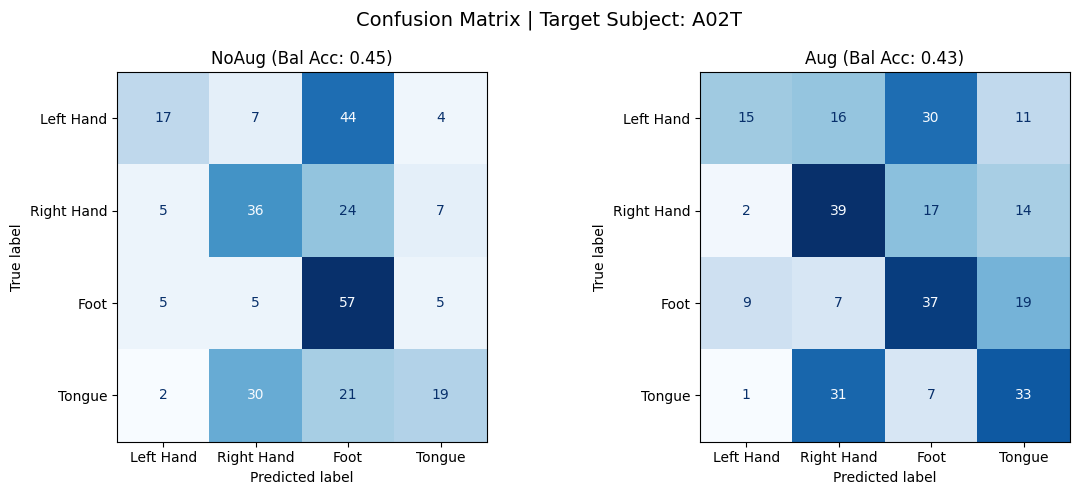


Fold 3/9 | Test Subject: A03T | Validation Subject: A04T

--- Training Condition: NoAug ---
Classification Report for Subject A03T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.70      0.69      0.70        72
  Right Hand       0.58      0.58      0.58        72
        Foot       0.51      0.79      0.62        72
      Tongue       0.97      0.44      0.61        72

    accuracy                           0.63       288
   macro avg       0.69      0.63      0.63       288
weighted avg       0.69      0.63      0.63       288


--- Training Condition: Aug ---
Classification Report for Subject A03T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.71      0.58      0.64        72
  Right Hand       0.62      0.60      0.61        72
        Foot       0.51      0.86      0.64        72
      Tongue       0.95      0.51      0.67        72

    accuracy                           0.64       288
   macro avg       

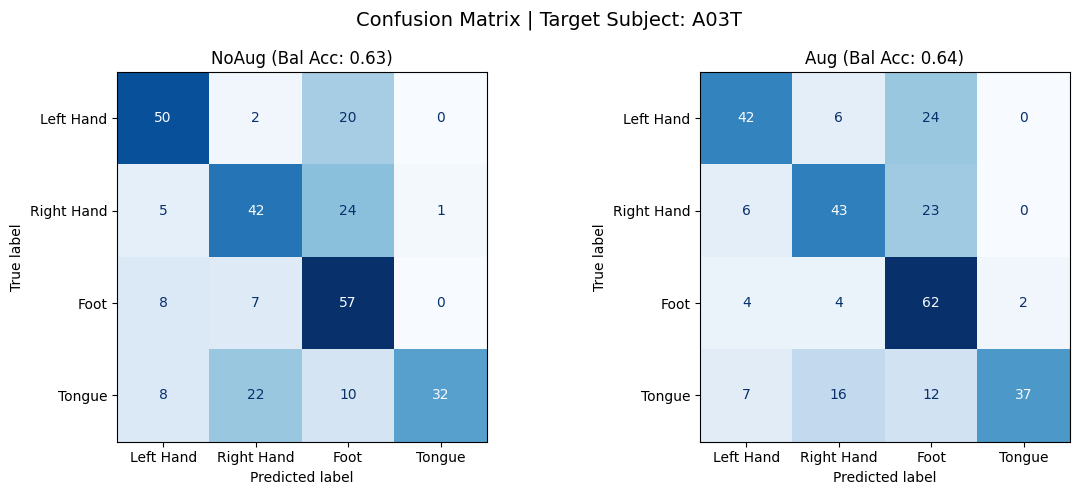


Fold 4/9 | Test Subject: A04T | Validation Subject: A05T

--- Training Condition: NoAug ---
Classification Report for Subject A04T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.58      0.51      0.54        72
  Right Hand       0.34      0.36      0.35        72
        Foot       0.40      0.67      0.50        72
      Tongue       0.78      0.29      0.42        72

    accuracy                           0.46       288
   macro avg       0.52      0.46      0.45       288
weighted avg       0.52      0.46      0.45       288


--- Training Condition: Aug ---
Classification Report for Subject A04T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.47      0.62      0.54        72
  Right Hand       0.33      0.29      0.31        72
        Foot       0.53      0.43      0.47        72
      Tongue       0.57      0.56      0.56        72

    accuracy                           0.48       288
   macro avg       

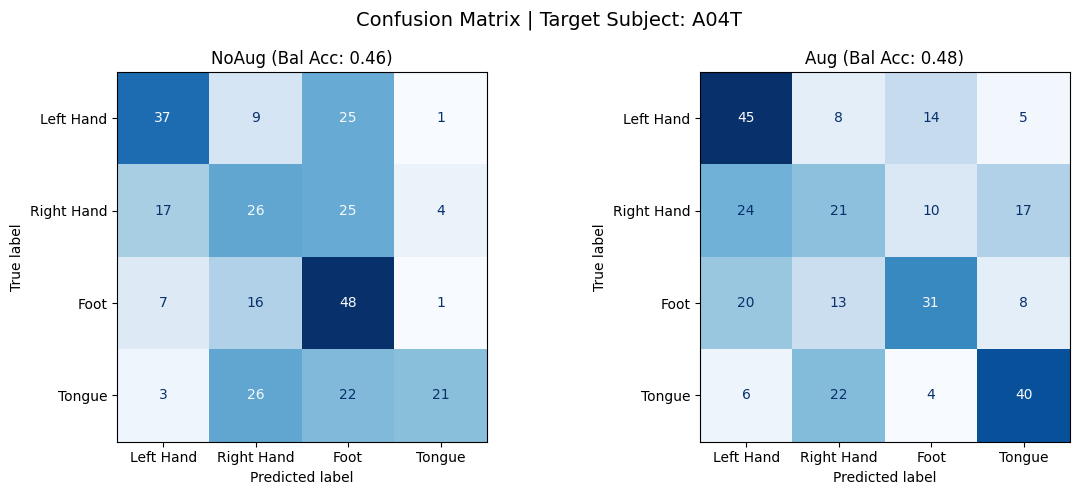


Fold 5/9 | Test Subject: A05T | Validation Subject: A06T

--- Training Condition: NoAug ---
Classification Report for Subject A05T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.54      0.35      0.42        72
  Right Hand       0.31      0.93      0.47        72
        Foot       0.79      0.32      0.46        72
      Tongue       0.00      0.00      0.00        72

    accuracy                           0.40       288
   macro avg       0.41      0.40      0.34       288
weighted avg       0.41      0.40      0.34       288


--- Training Condition: Aug ---
Classification Report for Subject A05T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.35      0.24      0.28        72
  Right Hand       0.30      0.83      0.44        72
        Foot       0.68      0.35      0.46        72
      Tongue       0.00      0.00      0.00        72

    accuracy                           0.35       288
   macro avg       

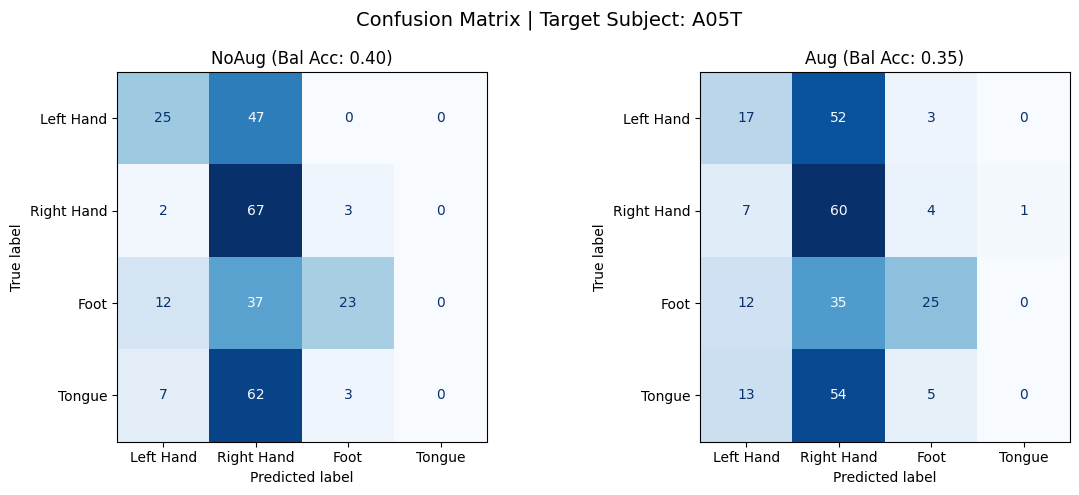


Fold 6/9 | Test Subject: A06T | Validation Subject: A07T

--- Training Condition: NoAug ---
Classification Report for Subject A06T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.70      0.64      0.67        72
  Right Hand       0.66      0.26      0.38        72
        Foot       0.51      0.64      0.57        72
      Tongue       0.50      0.71      0.58        72

    accuracy                           0.56       288
   macro avg       0.59      0.56      0.55       288
weighted avg       0.59      0.56      0.55       288


--- Training Condition: Aug ---
Classification Report for Subject A06T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.79      0.51      0.62        72
  Right Hand       0.56      0.25      0.35        72
        Foot       0.53      0.69      0.60        72
      Tongue       0.51      0.81      0.62        72

    accuracy                           0.57       288
   macro avg       

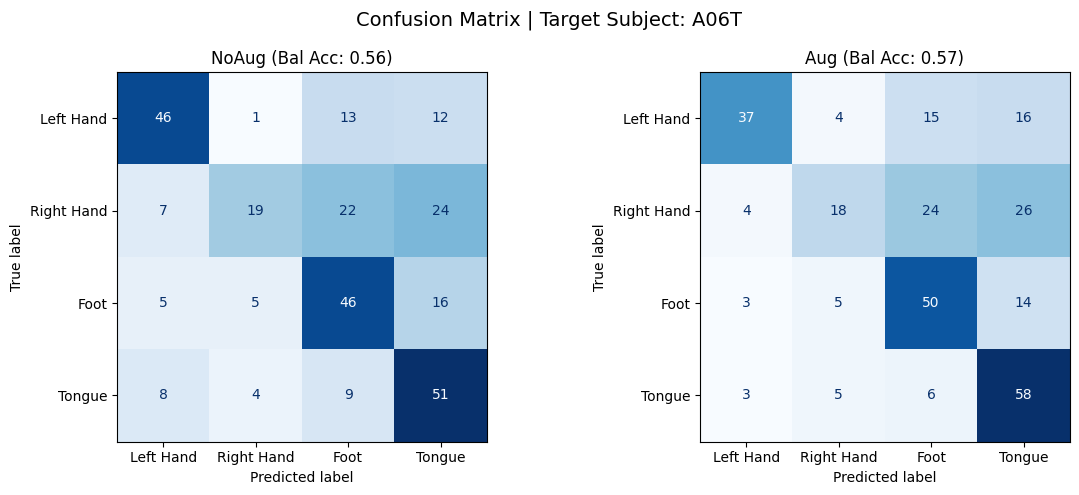


Fold 7/9 | Test Subject: A07T | Validation Subject: A08T

--- Training Condition: NoAug ---
Classification Report for Subject A07T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.39      0.51      0.44        72
  Right Hand       0.42      0.58      0.49        72
        Foot       0.78      0.35      0.48        72
      Tongue       0.62      0.51      0.56        72

    accuracy                           0.49       288
   macro avg       0.55      0.49      0.49       288
weighted avg       0.55      0.49      0.49       288


--- Training Condition: Aug ---
Classification Report for Subject A07T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.54      0.50      0.52        72
  Right Hand       0.47      0.71      0.57        72
        Foot       0.82      0.44      0.58        72
      Tongue       0.61      0.62      0.62        72

    accuracy                           0.57       288
   macro avg       

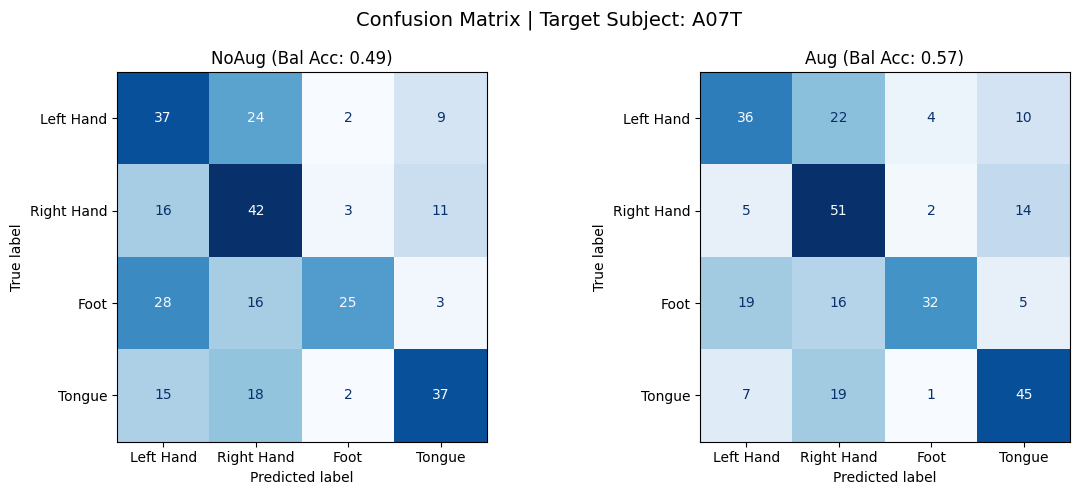


Fold 8/9 | Test Subject: A08T | Validation Subject: A09T

--- Training Condition: NoAug ---
Classification Report for Subject A08T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.52      0.53      0.52        72
  Right Hand       0.65      0.68      0.67        72
        Foot       0.65      0.24      0.35        72
      Tongue       0.54      0.85      0.66        72

    accuracy                           0.57       288
   macro avg       0.59      0.57      0.55       288
weighted avg       0.59      0.57      0.55       288


--- Training Condition: Aug ---
Classification Report for Subject A08T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.49      0.61      0.55        72
  Right Hand       0.76      0.53      0.62        72
        Foot       0.81      0.35      0.49        72
      Tongue       0.51      0.83      0.63        72

    accuracy                           0.58       288
   macro avg       

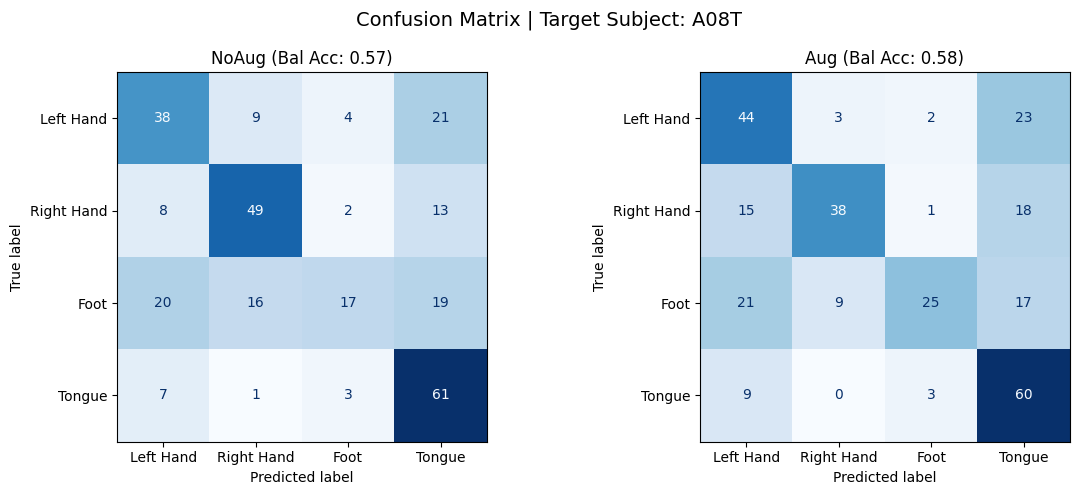


Fold 9/9 | Test Subject: A09T | Validation Subject: A01T

--- Training Condition: NoAug ---
Classification Report for Subject A09T (NoAug):
              precision    recall  f1-score   support

   Left Hand       0.72      0.67      0.69        72
  Right Hand       0.65      0.79      0.71        72
        Foot       0.63      0.53      0.58        72
      Tongue       0.77      0.78      0.77        72

    accuracy                           0.69       288
   macro avg       0.69      0.69      0.69       288
weighted avg       0.69      0.69      0.69       288


--- Training Condition: Aug ---
Classification Report for Subject A09T (Aug):
              precision    recall  f1-score   support

   Left Hand       0.79      0.51      0.62        72
  Right Hand       0.55      0.88      0.68        72
        Foot       0.59      0.57      0.58        72
      Tongue       0.86      0.69      0.77        72

    accuracy                           0.66       288
   macro avg       

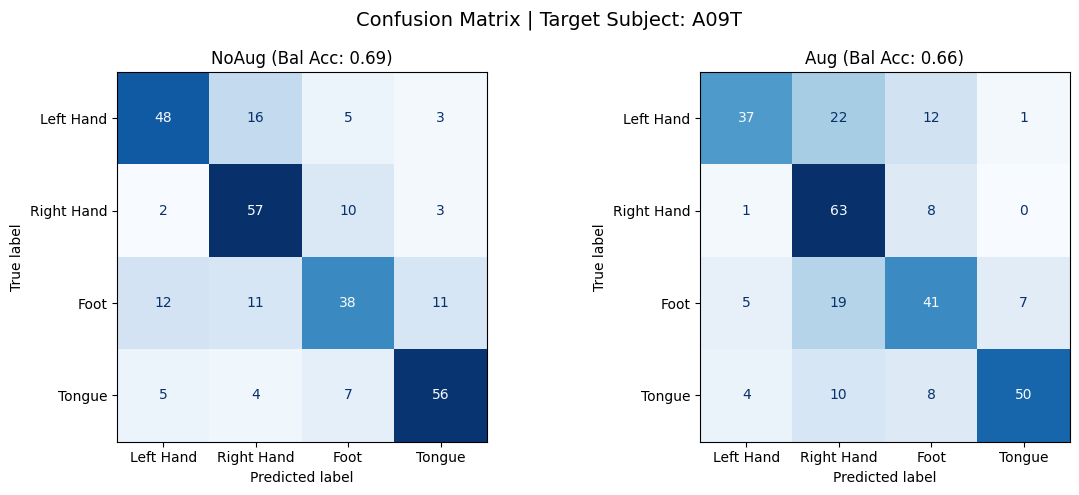


LOSO evaluation finished. Detailed results saved to 'loso_results.csv'.


In [12]:
if RUN_LOSO:
    print("Starting Leave-One-Subject-Out (LOSO) Evaluation with Detailed Reporting...\n")
    
    loso_results = []
    agg_preds = {'NoAug': [], 'Aug': []}
    agg_targets = {'NoAug': [], 'Aug': []}
    
    import time
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
    
    # Assicuriamoci che la cartella per i plot esista
    import os
    os.makedirs('saved_plots', exist_ok=True)
    
    for i, test_sub in enumerate(ALL_SUBJECTS):
        val_sub = ALL_SUBJECTS[(i + 1) % len(ALL_SUBJECTS)]
        train_subs = [s for s in ALL_SUBJECTS if s not in (test_sub, val_sub)]
        
        print(f"\n{'='*60}\nFold {i+1}/9 | Test Subject: {test_sub} | Validation Subject: {val_sub}\n{'='*60}")
        
        # Preparazione Dati
        X_tr_raw, y_tr_raw = stack(train_subs)
        X_va, y_va = stack([val_sub])
        X_te, y_te = stack([test_sub])
        
        # Generiamo direttamente i dati aumentati
        X_tr_aug, y_tr_aug = augment(X_tr_raw, y_tr_raw, std=NOISE_STD)
        
        # Dizionario per ciclare tra le due condizioni
        conditions = {
            "NoAug": (X_tr_raw, y_tr_raw),
            "Aug": (X_tr_aug, y_tr_aug)
        }
        
        # Setup plot per la Confusion Matrix
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        fig.suptitle(f'Confusion Matrix | Target Subject: {test_sub}', fontsize=14)
        
        for j, (cond_name, (X_tr, y_tr)) in enumerate(conditions.items()):
            print(f"\n--- Training Condition: {cond_name} ---")
            
            start_time = time.time()
            
            model, history, _ = build_and_train(
                X_tr, y_tr, X_va, y_va,
                lr=best_params['learning_rate'], 
                dropout=best_params['dropout_rate'],
                batch_size=best_params['batch_size'],
                epochs=LOSO_EPOCHS, 
                patience=LOSO_PATIENCE, 
                seed=SEED, 
                verbose=0
            )
            train_time = time.time() - start_time
            
            # Estrazione metriche dal training
            epochs_trained = len(history.history['loss'])
            best_val_loss = min(history.history['val_loss']) if 'val_loss' in history.history else 0.0
            
            # Inferenza
            preds_prob = model.predict(X_te, verbose=0)
            fold_preds = np.argmax(preds_prob, axis=1)
            fold_targets = np.argmax(y_te, axis=1) if len(y_te.shape) > 1 else y_te
            
            agg_preds[cond_name].extend(fold_preds)
            agg_targets[cond_name].extend(fold_targets)
            
            # Report di Classificazione
            print(f"Classification Report for Subject {test_sub} ({cond_name}):")
            report_str = classification_report(fold_targets, fold_preds, target_names=CLASS_NAMES, zero_division=0)
            print(report_str)
            
            # Estrazione metriche per salvataggio
            report_dict = classification_report(fold_targets, fold_preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
            
            acc = accuracy_score(fold_targets, fold_preds)
            balanced_acc = balanced_accuracy_score(fold_targets, fold_preds)
            
            loso_results.append({
                "Test Subject": test_sub,
                "Validation Subject": val_sub,
                "Condition": cond_name,
                "Accuracy": acc,
                "Balanced Accuracy": balanced_acc,
                "Macro Precision": report_dict['macro avg']['precision'],
                "Macro Recall": report_dict['macro avg']['recall'],
                "Macro F1": report_dict['macro avg']['f1-score'],
                "Weighted Precision": report_dict['weighted avg']['precision'],
                "Weighted Recall": report_dict['weighted avg']['recall'],
                "Weighted F1": report_dict['weighted avg']['f1-score'],
                "Train Time (s)": round(train_time, 1),
                "Best Val Loss": round(best_val_loss, 4),
                "Epochs Trained": epochs_trained
            })
            
            # Plot confusion matrix subplot
            cm = confusion_matrix(fold_targets, fold_preds)
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
            disp.plot(ax=axes[j], cmap='Blues', colorbar=False, values_format='d')
            axes[j].set_title(f'{cond_name} (Bal Acc: {balanced_acc:.2f})')

        plt.tight_layout()
        plt.savefig(f'saved_plots/CM_{test_sub}_Model.png')
        plt.show()

    # Salvataggio di tutti i risultati dettagliati su CSV
    results_df = pd.DataFrame(loso_results)
    results_df.to_csv("loso_results.csv", index=False)
    print("\nLOSO evaluation finished. Detailed results saved to 'loso_results.csv'.")
else:
    print('RUN_LOSO=False: skipped')

## Aggregate descriptive analysis and paired exploration

In [13]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

# Caricamento dati
results_df = pd.read_csv("loso_results.csv")

print("=== Cross-Subject Robustness (Mean +/- Std across 9 Folds) ===\n")
for cond in ['NoAug', 'Aug']:
    cond_df = results_df[results_df['Condition'] == cond]
    mean_bal_acc = cond_df['Balanced Accuracy'].mean()
    std_bal_acc = cond_df['Balanced Accuracy'].std()
    mean_f1 = cond_df['Macro F1'].mean()
    std_f1 = cond_df['Macro F1'].std()
    
    print(f"[{cond}] Balanced Accuracy: {mean_bal_acc:.3f} +/- {std_bal_acc:.3f}")
    print(f"[{cond}] Macro F1 Score:    {mean_f1:.3f} +/- {std_f1:.3f}\n")

print("=== Paired Per-Subject Performance ===\n")
# Pivot per affiancare NoAug e Aug per ogni soggetto
paired = results_df.pivot(
    index="Test Subject",
    columns="Condition",
    values=["Accuracy", "Balanced Accuracy", "Macro F1"]
)
# Appiattimento delle multi-colonne
paired.columns = [f"{metric}_{condition}" for metric, condition in paired.columns]

# Calcolo dei Delta
paired["BalancedAcc_Delta (Aug - NoAug)"] = paired["Balanced Accuracy_Aug"] - paired["Balanced Accuracy_NoAug"]
paired["MacroF1_Delta (Aug - NoAug)"] = paired["Macro F1_Aug"] - paired["Macro F1_NoAug"]

# Utilizza display() in un notebook, altrimenti usa print()
try:
    display(paired[['Balanced Accuracy_NoAug', 'Balanced Accuracy_Aug', 'BalancedAcc_Delta (Aug - NoAug)',
                    'Macro F1_NoAug', 'Macro F1_Aug', 'MacroF1_Delta (Aug - NoAug)']].round(3))
except NameError:
    print(paired[['Balanced Accuracy_NoAug', 'Balanced Accuracy_Aug', 'BalancedAcc_Delta (Aug - NoAug)',
                  'Macro F1_NoAug', 'Macro F1_Aug', 'MacroF1_Delta (Aug - NoAug)']].round(3))

# Test Statistico Esplorativo
delta = paired["BalancedAcc_Delta (Aug - NoAug)"]
# Il test di Wilcoxon ha bisogno di scartare le differenze esatte a zero
# Se tutti i delta sono identici a zero lancerà un warning, gestiamolo
try:
    stat, p_value = wilcoxon(delta)
    print("\n=== Statistical Exploration ===")
    print(f"Wilcoxon statistic on Balanced Accuracy Deltas: {stat:.3f}")
    print(f"Exploratory paired p-value: {p_value:.4f}")
except ValueError as e:
    print("\n=== Statistical Exploration ===")
    print(f"Could not perform Wilcoxon test (likely all deltas are exactly zero). Error: {e}")

print("\n(Note: Given the small sample size of n=9 subjects, effect sizes and per-subject consistency are prioritized over binary significance claims).")

=== Cross-Subject Robustness (Mean +/- Std across 9 Folds) ===

[NoAug] Balanced Accuracy: 0.532 +/- 0.093
[NoAug] Macro F1 Score:    0.518 +/- 0.106

[Aug] Balanced Accuracy: 0.540 +/- 0.100
[Aug] Macro F1 Score:    0.527 +/- 0.115

=== Paired Per-Subject Performance ===



,Balanced Accuracy_NoAug,Balanced Accuracy_Aug,BalancedAcc_Delta (Aug - NoAug),Macro F1_NoAug,Macro F1_Aug,MacroF1_Delta (Aug - NoAug)
Test Subject,,,,,,
A01T,0.542,0.583,0.042,0.539,0.572,0.032
A02T,0.448,0.431,-0.017,0.424,0.418,-0.006
A03T,0.628,0.639,0.010,0.628,0.640,0.012
A04T,0.458,0.476,0.017,0.454,0.471,0.017
A05T,0.399,0.354,-0.045,0.337,0.295,-0.043
A06T,0.562,0.566,0.003,0.548,0.548,-0.001
A07T,0.490,0.569,0.080,0.493,0.569,0.077
A08T,0.573,0.580,0.007,0.548,0.572,0.023
A09T,0.691,0.663,-0.028,0.688,0.663,-0.025



=== Statistical Exploration ===
Wilcoxon statistic on Balanced Accuracy Deltas: 18.000
Exploratory paired p-value: 0.6523

(Note: Given the small sample size of n=9 subjects, effect sizes and per-subject consistency are prioritized over binary significance claims).


## Ablation visualization

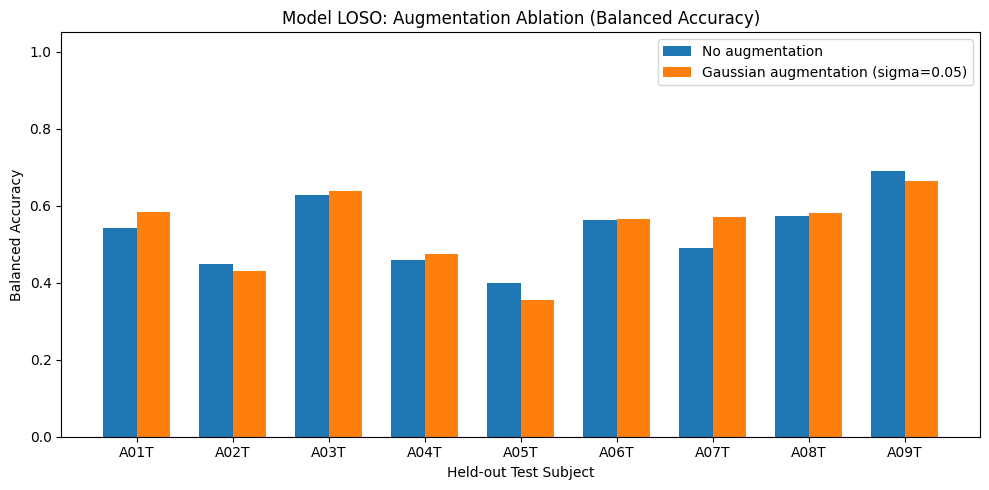

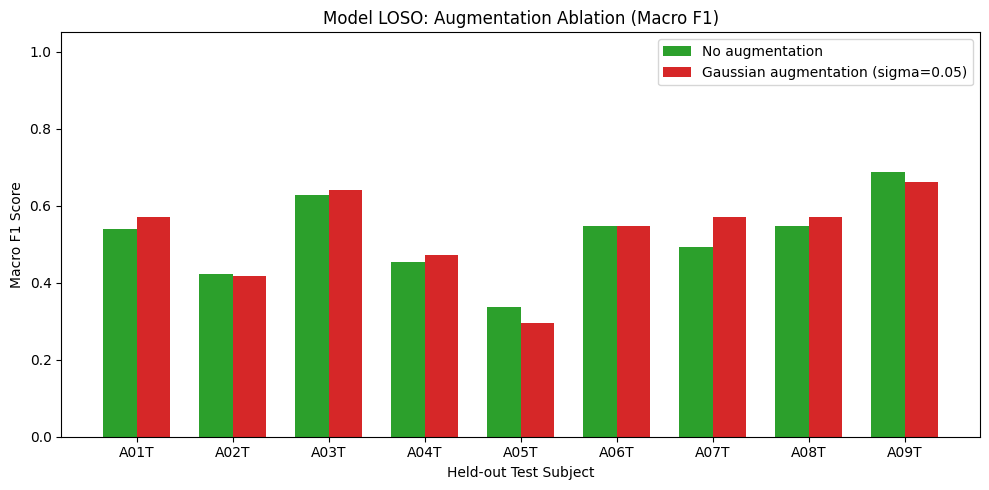

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Assicuriamoci che la cartella esista
os.makedirs("saved_plots", exist_ok=True)

# Prepariamo il DataFrame per il plot resettando l'indice (che attualmente è "Test Subject")
plot_df = paired.reset_index()

# ---------------------------------------------------------
# 1. Plot: Balanced Accuracy (Augmentation Ablation)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
x = np.arange(len(plot_df))
width = 0.35

plt.bar(x - width / 2, plot_df["Balanced Accuracy_NoAug"], width, label="No augmentation", color='#1f77b4')
plt.bar(x + width / 2, plot_df["Balanced Accuracy_Aug"], width, label=f"Gaussian augmentation (sigma={NOISE_STD})", color='#ff7f0e')

plt.xticks(x, plot_df["Test Subject"])
plt.ylim(0, 1.05) # Aumentato leggermente per far respirare la legenda
plt.ylabel("Balanced Accuracy")
plt.xlabel("Held-out Test Subject")
# Puoi cambiare "EEGNet" con "AttentionBaseNet" a seconda del modello in uso
plt.title("Model LOSO: Augmentation Ablation (Balanced Accuracy)")
plt.legend(loc='upper right')
plt.tight_layout()

plt.savefig("saved_plots/BalancedAccuracy_Augmentation_Ablation.png", dpi=200)
plt.show()

# ---------------------------------------------------------
# 2. Plot: Macro F1 Score (Augmentation Ablation)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))

plt.bar(x - width / 2, plot_df["Macro F1_NoAug"], width, label="No augmentation", color='#2ca02c')
plt.bar(x + width / 2, plot_df["Macro F1_Aug"], width, label=f"Gaussian augmentation (sigma={NOISE_STD})", color='#d62728')

plt.xticks(x, plot_df["Test Subject"])
plt.ylim(0, 1.05)
plt.ylabel("Macro F1 Score")
plt.xlabel("Held-out Test Subject")
plt.title("Model LOSO: Augmentation Ablation (Macro F1)")
plt.legend(loc='upper right')
plt.tight_layout()

plt.savefig("saved_plots/MacroF1_Augmentation_Ablation.png", dpi=200)
plt.show()

## 6. Results and discussion

### Performance overview
EEGNet was trained on subjects `TRAIN_SUBJECTS`, tuned on `VAL_SUBJECTS` and evaluated once on the unseen subjects `TEST_SUBJECTS`: **test accuracy = 47.0%** (chance level for 4 balanced classes = 25%). 
As expected in cross-subject BCI decoding, there is high inter-subject variability: Subject A09T reached an accuracy of 55.9%, while Subject A02T stopped at 38.2%. While lower than intra-subject or data-leaked models, this 47% represents a rigorous, realistic subject-independent baseline, proving the model is extracting genuine neurophysiological patterns rather than overfitting to stochastic session noise.

### Class-specific analysis
Based on the classification report, **Tongue** imagery is the best-separated class (F1-score = 0.54), driven by a high precision of 0.65. This aligns with physiological expectations, as the tongue's cortical representation is lateral and highly distinct from the limbs. **Right Hand** also performed reasonably well (F1-score = 0.50) with the highest recall (0.58). Conversely, **Left Hand** was the hardest class to decode (F1-score = 0.39), suffering from a very low recall (0.30), meaning it was frequently misclassified as other motor tasks. The low precision for **Foot** (0.37) indicates that other classes were often wrongly predicted as foot movement, reflecting the classic BCI challenge of resolving the central medial areas of the motor homunculus.

### Effect of the design choices
The ablation study on the validation subjects reveals that the frequency band selection was the most critical factor. The wide-band **1-40 Hz** approach (mean val_acc = 0.531) drastically outperformed the narrower **8-30 Hz** band (mean val_acc = 0.350). This gap of 18 percentage points is highly significant and well beyond the seed-to-seed standard deviation (0.014 - 0.025). 
Conversely, **Gaussian noise augmentation** (mean val_acc = 0.534) provided only a marginal +0.3% improvement over the unaugmented 1-40 Hz baseline. Since this difference is completely absorbed by the random seed standard deviation (0.024), we can conclude that for this specific architecture and dataset, the performance gain is entirely attributable to the wider frequency band rather than data augmentation.

### LOSO Cross-Subject performance

The nine-fold leave-one-subject-out (LOSO) evaluation provides an assessment of EEGNet's ability to generalize to unseen participants. Without augmentation, the model achieved a mean balanced accuracy of **53.2% ± 9.3%** and a mean macro-F1 score of **51.8% ± 10.6%**. With Gaussian-noise augmentation, these values increased slightly to **54.0% ± 10.0%** and **52.7% ± 11.5%**, respectively.

The absolute improvements were modest: 0.8 percentage points in balanced accuracy and 0.9 percentage points in macro-F1. These results suggest that Gaussian augmentation may provide a small average benefit, but the improvement is not consistent enough to establish a reliable advantage. The paired Wilcoxon signed-rank test yielded \(p = 0.6523\), which does not provide statistically significant evidence of a difference between the two conditions at the 0.05 level.

The standard deviations across the nine held-out subjects indicate substantial inter-subject variability. This variability highlights the difficulty of cross-subject motor-imagery decoding and suggests that the effectiveness of augmentation may depend on the characteristics of individual participants.

Importantly, the absence of statistical significance does not demonstrate that the two conditions are equivalent. With only nine subjects, the statistical analysis has limited power to detect small effects. Therefore, the results should be interpreted as showing a modest descriptive improvement, rather than a demonstrated benefit of Gaussian augmentation.

### Limitations
* Single fixed split of subjects (two test subjects); the figure depends on which subjects are held out.
* Hyper-parameters tuned on only two validation subjects.
* LOSO analysis includes only nine participants, limiting the precision of the estimated average performance and the power of the paired statistical test. 
* The ablation uses only three random seeds and two validation participants, so the frequency-band findings require further confirmation.




Overall, the results support EEGNet as a cross-subject baseline with moderate performance and substantial participant-to-participant variability. Under the tested conditions, Gaussian-noise augmentation produced only small descriptive gains, while the frequency-band ablation favored the broader 1–40 Hz representation. Further experiments with matched optimization budgets, more random seeds, and fully nested model selection would help establish the robustness of these observations.




